In [1]:
import time
import pickle
import tracemalloc
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

warnings.filterwarnings("ignore")

In [4]:
try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [6]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=8,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        C=1.0
    ),

    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(32, 16),
        max_iter=500,
        early_stopping=True,
        random_state=42
    )
}

In [7]:
results = []

for name, model in models.items():

    print("\nTesting:", name)

    
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    tracemalloc.start()

    start_time = time.perf_counter()

    pipeline.fit(X_train, y_train)

    training_time = time.perf_counter() - start_time

    current_memory, peak_memory = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    pipeline.predict(X_test[:1]) 

    prediction_repeats = 20

    start_time = time.perf_counter()

    for _ in range(prediction_repeats):
        predictions = pipeline.predict(X_test)

    total_prediction_time = time.perf_counter() - start_time

    prediction_time = (
        total_prediction_time / prediction_repeats
    )

    inference_per_sample = (
        prediction_time / len(X_test)
    )

    model_bytes = pickle.dumps(
        pipeline,
        protocol=pickle.HIGHEST_PROTOCOL
    )

    model_size_kb = len(model_bytes) / 1024

    predictions = pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        predictions,
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Training Time (sec)": training_time,
        "Prediction Time (sec)": prediction_time,
        "Inference per Sample (ms)": inference_per_sample * 1000,
        "Peak Python Memory (MB)": peak_memory / (1024 ** 2),
        "Model Size (KB)": model_size_kb
    })

    print("Accuracy:", round(accuracy, 4))
    print("F1 Score:", round(f1, 4))
    print("Training Time:", round(training_time, 4), "seconds")
    print("Prediction Time:", round(prediction_time, 4), "seconds")
    print("Model Size:", round(model_size_kb, 2), "KB")


Testing: Logistic Regression
Accuracy: 0.8033
F1 Score: 0.8235
Training Time: 0.0372 seconds
Prediction Time: 0.0022 seconds
Model Size: 1.99 KB

Testing: Decision Tree
Accuracy: 0.7705
F1 Score: 0.7812
Training Time: 0.0205 seconds
Prediction Time: 0.0016 seconds
Model Size: 5.65 KB

Testing: Random Forest
Accuracy: 0.7705
F1 Score: 0.7879
Training Time: 1.1267 seconds
Prediction Time: 0.008 seconds
Model Size: 627.01 KB

Testing: KNN
Accuracy: 0.7869
F1 Score: 0.8116
Training Time: 0.0132 seconds
Prediction Time: 0.0056 seconds
Model Size: 34.04 KB

Testing: SVM
Accuracy: 0.7705
F1 Score: 0.7941
Training Time: 0.0135 seconds
Prediction Time: 0.0023 seconds
Model Size: 19.52 KB

Testing: Neural Network
Accuracy: 0.7213
F1 Score: 0.7119
Training Time: 0.1195 seconds
Prediction Time: 0.0017 seconds
Model Size: 32.14 KB


In [8]:
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE AND RESOURCE COMPARISON")
print(results_df.round(4).to_string(index=False))

results_df.to_csv(
    "model_resource_comparison.csv",
    index=False
)


MODEL PERFORMANCE AND RESOURCE COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  Training Time (sec)  Prediction Time (sec)  Inference per Sample (ms)  Peak Python Memory (MB)  Model Size (KB)
Logistic Regression    0.8033     0.8000  0.8485    0.8235               0.0372                 0.0022                     0.0365                   0.1509           1.9854
      Decision Tree    0.7705     0.8065  0.7576    0.7812               0.0205                 0.0016                     0.0262                   0.1409           5.6523
      Random Forest    0.7705     0.7879  0.7879    0.7879               1.1267                 0.0080                     0.1318                   0.1573         627.0137
                KNN    0.7869     0.7778  0.8485    0.8116               0.0132                 0.0056                     0.0917                   0.1415          34.0391
                SVM    0.7705     0.7714  0.8182    0.7941               0.0135                 0

In [9]:
results_df["Performance Rank"] = (
    results_df["F1 Score"]
    .rank(ascending=False, method="min")
)

results_df["Training Rank"] = (
    results_df["Training Time (sec)"]
    .rank(ascending=True, method="min")
)

results_df["Inference Rank"] = (
    results_df["Inference per Sample (ms)"]
    .rank(ascending=True, method="min")
)

results_df["Memory Rank"] = (
    results_df["Model Size (KB)"]
    .rank(ascending=True, method="min")
)

results_df["Overall Rank"] = results_df[
    [
        "Performance Rank",
        "Training Rank",
        "Inference Rank",
        "Memory Rank"
    ]
].mean(axis=1)

results_df = results_df.sort_values(
    "Overall Rank"
).reset_index(drop=True)

print("\nOVERALL MODEL RANKING")
print(
    results_df[
        ["Model", "F1 Score", "Training Time (sec)",
         "Inference per Sample (ms)", "Model Size (KB)",
         "Overall Rank"]
    ].round(4).to_string(index=False)
)


OVERALL MODEL RANKING
              Model  F1 Score  Training Time (sec)  Inference per Sample (ms)  Model Size (KB)  Overall Rank
Logistic Regression    0.8235               0.0372                     0.0365           1.9854          2.25
      Decision Tree    0.7812               0.0205                     0.0262           5.6523          2.75
                SVM    0.7941               0.0135                     0.0376          19.5166          3.00
                KNN    0.8116               0.0132                     0.0917          34.0391          3.25
     Neural Network    0.7119               0.1195                     0.0282          32.1377          4.25
      Random Forest    0.7879               1.1267                     0.1318         627.0137          5.50


In [10]:
best_model = results_df.iloc[0]

print("\nRECOMMENDED MODEL")
print("------------------------")
print("Model:", best_model["Model"])
print("F1 Score:", round(best_model["F1 Score"], 4))
print(
    "Training Time:",
    round(best_model["Training Time (sec)"], 4),
    "seconds"
)
print(
    "Inference per Sample:",
    round(best_model["Inference per Sample (ms)"], 4),
    "ms"
)
print(
    "Model Size:",
    round(best_model["Model Size (KB)"], 2),
    "KB"
)


RECOMMENDED MODEL
------------------------
Model: Logistic Regression
F1 Score: 0.8235
Training Time: 0.0372 seconds
Inference per Sample: 0.0365 ms
Model Size: 1.99 KB


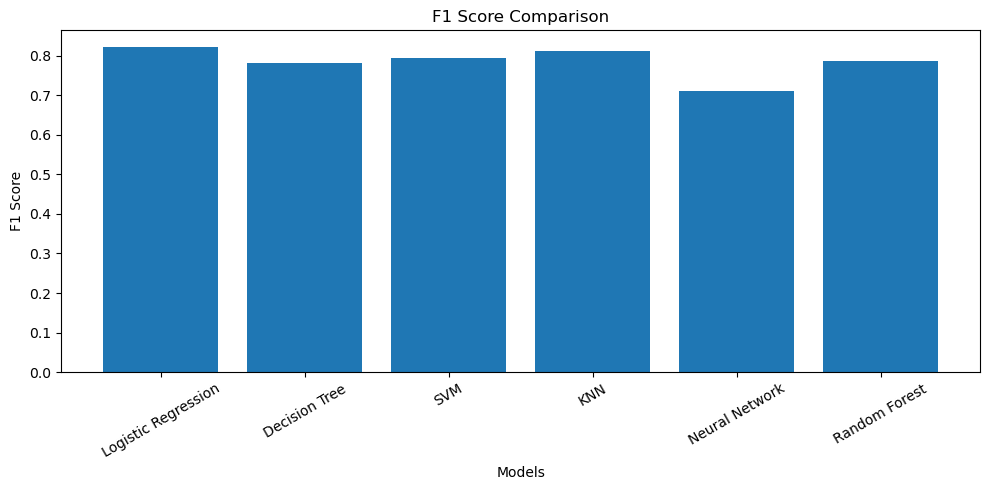

In [11]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["F1 Score"]
)

plt.title("F1 Score Comparison")
plt.xlabel("Models")
plt.ylabel("F1 Score")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

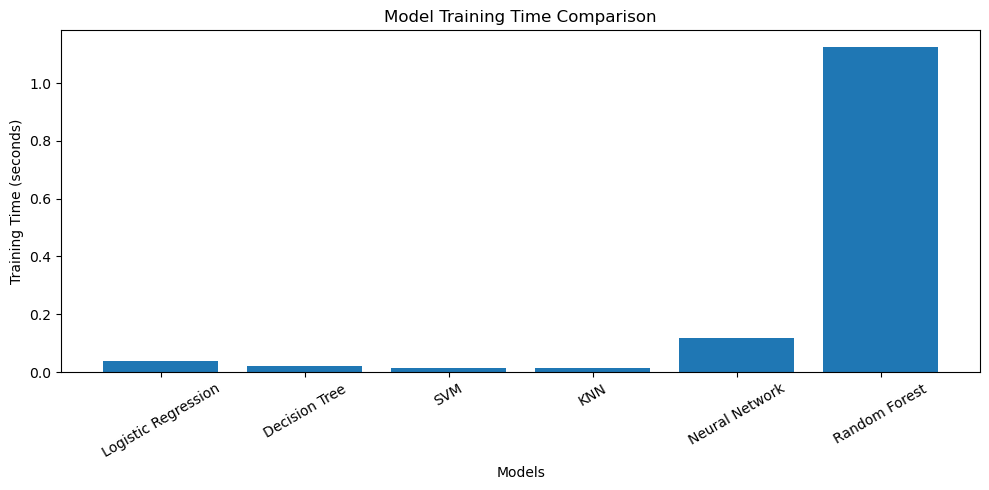

In [12]:

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Training Time (sec)"]
)

plt.title("Model Training Time Comparison")
plt.xlabel("Models")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

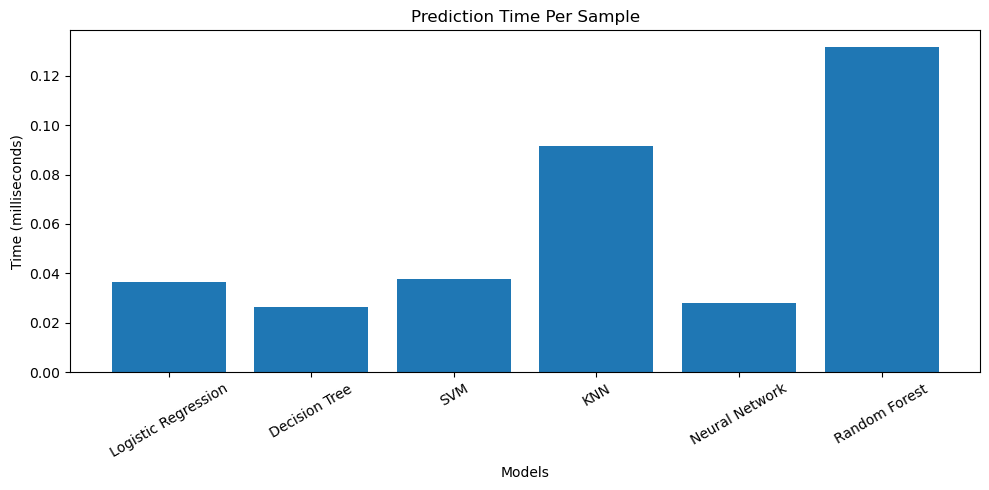

In [13]:


plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Inference per Sample (ms)"]
)

plt.title("Prediction Time Per Sample")
plt.xlabel("Models")
plt.ylabel("Time (milliseconds)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

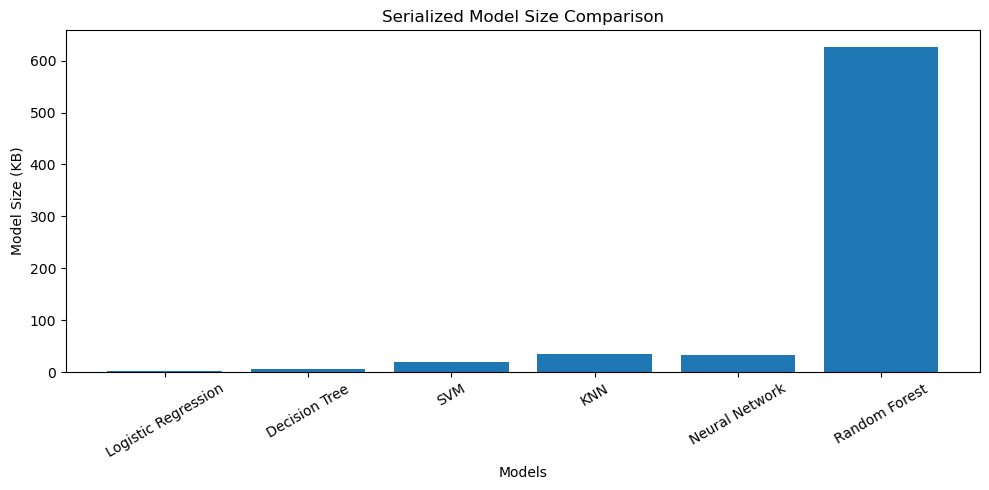

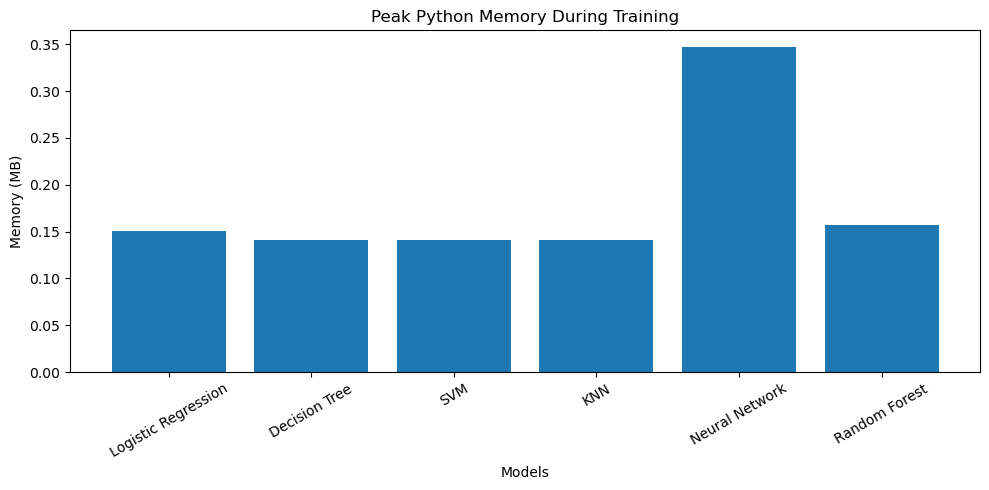

In [14]:


plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Model Size (KB)"]
)

plt.title("Serialized Model Size Comparison")
plt.xlabel("Models")
plt.ylabel("Model Size (KB)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Model"],
    results_df["Peak Python Memory (MB)"]
)

plt.title("Peak Python Memory During Training")
plt.xlabel("Models")
plt.ylabel("Memory (MB)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

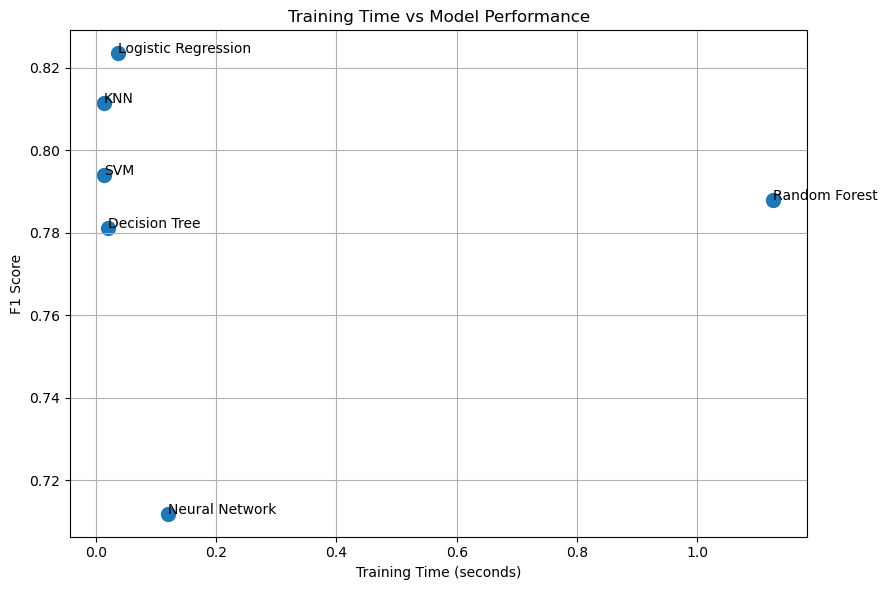

In [15]:

plt.figure(figsize=(9, 6))

plt.scatter(
    results_df["Training Time (sec)"],
    results_df["F1 Score"],
    s=100
)

for _, row in results_df.iterrows():
    plt.annotate(
        row["Model"],
        (
            row["Training Time (sec)"],
            row["F1 Score"]
        )
    )

plt.title("Training Time vs Model Performance")
plt.xlabel("Training Time (seconds)")
plt.ylabel("F1 Score")
plt.grid(True)
plt.tight_layout()
plt.show()

In [16]:

print("\nDEPLOYMENT ANALYSIS")
print("------------------------")

fastest_model = results_df.loc[
    results_df["Inference per Sample (ms)"].idxmin()
]

smallest_model = results_df.loc[
    results_df["Model Size (KB)"].idxmin()
]

best_performance_model = results_df.loc[
    results_df["F1 Score"].idxmax()
]

print("Best Overall Balance:", best_model["Model"])
print("Fastest Prediction:", fastest_model["Model"])
print("Smallest Model:", smallest_model["Model"])
print("Best F1 Performance:", best_performance_model["Model"])

print("\nAnalysis completed successfully.")




DEPLOYMENT ANALYSIS
------------------------
Best Overall Balance: Logistic Regression
Fastest Prediction: Decision Tree
Smallest Model: Logistic Regression
Best F1 Performance: Logistic Regression

Analysis completed successfully.
